In [ ]:
import sys
!uv pip install --python {sys.executable} healpy

In [ ]:
import sys
!uv pip install --python {sys.executable} healpix

In [1]:
import pandas as pd
from scipy.stats import uniform, gamma
from astro_prost.associate import associate_sample
import skyproj
import os
import matplotlib.pyplot as plt
import numpy as np
import healpy as hp

print("pandas", pd.__version__) 

pandas 2.3.3


In [2]:
raw = pd.read_parquet("Result/snia_results.parquet")
print("rows:", len(raw))
print("missing tns_name:", raw["tns_name"].isna().sum())
print("missing ra / decl:", raw["ra"].isna().sum(), "/", raw["decl"].isna().sum())
print("duplicated tns_name (excluding missing):", raw["tns_name"].dropna().duplicated().sum())
print("duplicated diaObjectId:", raw["diaObjectId"].duplicated().sum())

rows: 127
missing tns_name: 0
missing ra / decl: 0 / 0
duplicated tns_name (excluding missing): 26
duplicated diaObjectId: 0


In [3]:
df = (
    raw.dropna(subset=["tns_name", "ra", "decl"])
       .sort_values("nDiaSources", ascending=False)
       .drop_duplicates(subset="tns_name", keep="first")
       .sort_index()
       .rename(columns={"tns_name": "name", "decl": "dec"})
       .reset_index(drop=True)
)

print(df.shape)    
# For instance, this is an example of one of the duplicated TNS entries. We keep the entry with the largest "nDiaSources"
display(df[df["name"] == "2021hiz"][["name", "diaObjectId", "nDiaSources"]]) 

(101, 10)


,name,diaObjectId,nDiaSources
8,2021hiz,170028527695429710,24


In [4]:
display(df)

,diaObjectId,name,z,catalogue_object_id,tns_prefix,type,ra,dec,absMag,nDiaSources
0,170019717277810735,2026ctw,0.150000,"10000,342494,11570",SN,SN Ia,151.740293,1.927064,NaN,754
1,170028486191218743,2026qrh,0.100000,"10000,81273,866",SN,SN Ia,64.185342,-48.943229,NaN,88
2,170028500610711681,2024xom,0.044167,CGCG036-024,SN,SN Ia,150.746125,2.336469,NaN,165
3,170028510695916335,2025mbp,0.046160,2MASXJ10062208+0109317,SN,SN Ia,151.592617,1.158385,NaN,273
4,170028526486945858,2026fgt,0.282000,115901861891057367,SN,SN Ia,186.188879,6.589125,NaN,538
...,...,...,...,...,...,...,...,...,...,...
96,170648615579549734,2026uxs,0.115000,"10000,290964,1056",SN,SN Ia,210.988573,-6.980285,NaN,3
97,170653057310261886,2025nou,0.040716,2MASXJ22041416-0159498,SN,SN Ia,331.058529,-1.997490,NaN,2
98,170657505023098990,2026tzm,0.180000,1237663784196047153,SN,SN Ia,356.991032,0.193536,-19.0089,2
99,170661828398940941,2025bbx,0.067000,14470795-3930390,SN,SN Ia,221.785403,-39.509297,NaN,3


In [ ]:
transients_dict = df.set_index("name").to_dict(orient="index")

N_TEST = None
transient_catalog = df[["name", "ra", "dec"]].head(N_TEST)

In [ ]:
catalogs = ["glade", "decals", "panstarrs"]

priors = {"offset": uniform(loc=0, scale=10)}
likes = {"offset": gamma(a=0.75)}

hosts = associate_sample(
    transient_catalog,
    priors=priors,
    likes=likes,
    catalogs=catalogs,
    name_col="name",
    coord_cols=("ra", "dec"),
    parallel=False,
    save=False,
)

print(hosts.columns.tolist())
display(hosts)

In [ ]:
matched = hosts.dropna(subset=["host_objID"])
print(f"{len(matched)} of {len(hosts)} transients got a host")

hosts.to_csv("hosts.csv", index=False)

/Users/luzangela/Team3_SNe_Host_Matching/.venv/lib/python3.12/site-packages/skyproj/_skyproj.py:621: FutureWarning: skyproj.plot() has been deprecated and will be removed in v2.5. Please access via skyproj.ax.plot()
  warnings.warn(


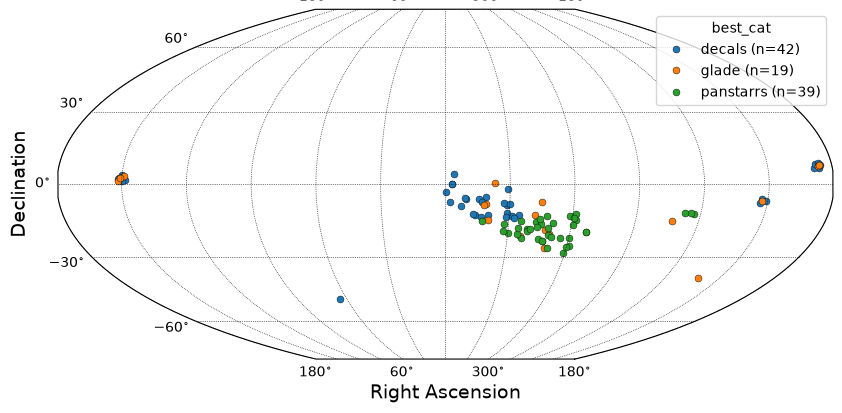

In [11]:
hosts = pd.read_csv("hosts.csv")
colors = {"glade": "tab:orange", "decals": "tab:blue", "panstarrs": "tab:green"}

fig, ax = plt.subplots(figsize=(10, 6))
sp = skyproj.McBrydeSkyproj(ax=ax)
"""
if os.path.exists("tract_vertices.csv"):
    tv = pd.read_csv("tract_vertices.csv")
    for tract, g in tv.groupby("tract"):
        sp.draw_polygon(g["ra"].values, g["dec"].values,
                        edgecolor="darkgrey", alpha=1, linewidth=0.5, facecolor=None)
else:
    print("tract_vertices.csv not found: plotting hosts only")
"""
for cat, g in hosts.groupby("best_cat"):
    sp.plot(g["ra"].values, g["dec"].values, marker="o", linestyle="none",
            markersize=5, color=colors[cat], markeredgecolor="k", markeredgewidth=0.3,
            label=f"{cat} (n={len(g)})")

sp.ax.set_xlabel("Right Ascension", fontsize=14)
sp.ax.set_ylabel("Declination", fontsize=14)
sp.ax.legend(title="best_cat", loc="upper right")
plt.show()

In [9]:
print('One 19-sided HEALPix is ', np.round(hp.nside2pixarea(19, degrees=True), 2),
      ' square degrees.')
print('It takes ', int(41253.0 / hp.nside2pixarea(19, degrees=True)),
      ' 19-sided HEALPix to cover the full sky.')

One 19-sided HEALPix is  9.52  square degrees.
It takes  4332  19-sided HEALPix to cover the full sky.


/Users/luzangela/Team3_SNe_Host_Matching/.venv/lib/python3.12/site-packages/skyproj/skyaxes.py:443: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  legend = super().legend(*args, loc=loc, **kwargs)


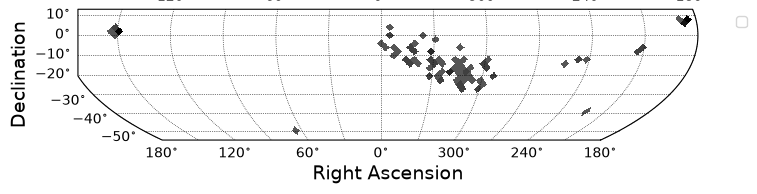

In [10]:
fig, ax = plt.subplots(figsize=(8, 6))
sp = skyproj.McBrydeSkyproj(ax=ax)
vras = np.asarray(hosts["ra"], dtype="float")
vdecs = np.asarray(hosts["dec"], dtype="float")
sp.draw_hpxbin(vras, vdecs, nside=19, alpha=1, cmap='Greys', vmin=-10)
sp.ax.set_xlabel("Right Ascension", fontsize=14)
sp.ax.set_ylabel("Declination", fontsize=14)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

In [ ]:
hosts = pd.read_csv("hosts.csv")

colors = {"glade": "tab:orange", "decals": "tab:blue", "panstarrs": "tab:green"}

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection="mollweide")

for cat, g in hosts.groupby("best_cat"):
    x = np.radians(g["ra"].values - 180)   # RA 0-360 -> -180..180, increasing to the right
    y = np.radians(g["dec"].values)
    ax.scatter(x, y, s=10, color=colors[cat], edgecolor="k", linewidth=0.3,
               label=f"{cat} (n={len(g)})")

ax.set_xticks(np.radians(np.arange(-150, 151, 30)))
ax.set_xticklabels([f"{d}°" for d in np.arange(30, 331, 30)])
ax.grid(True, linestyle=":", linewidth=0.6)
ax.set_xlabel("Right Ascension", fontsize=14)
ax.set_ylabel("Declination", fontsize=14)
ax.legend(title="Best catalog", loc="upper right")

fig.savefig("hosts_skymap_SNIa.png", dpi=200, bbox_inches="tight")
plt.show()